# TinyML 2026 · Del entrenamiento en Google Colab a Arduino Nano 33 BLE Sense

**Práctica guiada | Introducción al TinyML | Versión 1.0 — 26 de octubre de 2026**

**Objetivo:** entrenar una red neuronal que aproxime $y=\sin(x)$, evaluar su desempeño, cuantizarla a **INT8**, convertirla a un modelo **TensorFlow Lite (`.tflite`)**, incorporarla como un arreglo C/C++ en `model.h` y generar un **sketch para Arduino IDE 2.x** que ejecute inferencia real con TensorFlow Lite Micro.

> **Placas:** Arduino Nano 33 BLE Sense (original) y **Nano 33 BLE Sense Rev2**, así como otras placas ARM Mbed compatibles. Para una primera práctica no se usan micrófono ni IMU; por lo tanto, el cambio de sensores entre Rev1 y Rev2 no afecta a este ejemplo. La biblioteca empleada es **Chirale_TensorFlowLite 2.0.0 (2024)**, una adaptación Arduino de TFLM. Es de terceros y conviene validar la compilación con la versión de Arduino Mbed OS Nano Boards que se instale.

**Entregables automáticos de este notebook:**
- `modelo_seno_int8.tflite`: modelo cuantizado.
- `model.h`: bytes del modelo, alineados para el microcontrolador.
- `TinyML_Seno_Nano33BLE.ino`: sketch de inferencia y salida al Serial Plotter.
- `README_Arduino.txt`: instrucciones para Arduino IDE.
- `metricas.json`: parámetros de cuantización y resultados.
- `TinyML_Seno_Arduino_Nano33BLE.zip`: proyecto Arduino listo para extraer y abrir.

**No necesitas hardware durante el entrenamiento.** La carga y ejecución en Arduino se realizan después, desde tu computadora.

**Referencias:** [TFLM principal](https://github.com/tensorflow/tflite-micro) · [Chirale Arduino](https://github.com/spaziochirale/Chirale_TensorFlowLite) · [Arduino Mbed OS Nano Boards](https://docs.arduino.cc/software/ide-v1/tutorials/getting-started/cores/arduino-mbed_nano/) · [Ejemplo histórico de Hello World](https://github.com/tensorflow/tflite-micro-arduino-examples/tree/main/examples/hello_world).

## 0. Preparar el entorno de Colab

Abre este `.ipynb` en Google Colab y elige **Entorno de ejecución → Ejecutar todo**. Colab normalmente incluye TensorFlow, NumPy y Matplotlib. Si `import tensorflow` falla, ejecuta primero `!pip -q install tensorflow` y reinicia el entorno.

Para reproducibilidad fijamos semillas. La versión de TensorFlow del entorno se imprime para registrar qué herramienta generó el FlatBuffer; **TFLM en Arduino y TensorFlow de Colab no son exactamente la misma biblioteca**.

In [1]:
import sys, json, math, zipfile, textwrap
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 2026
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT = Path('/tinyml_seno') if Path('/content').is_dir() else Path('tinyml_seno')
OUTPUT.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('NumPy:', np.__version__)
print('Archivos en:', OUTPUT.resolve())

Python: 3.14.3
TensorFlow: 2.22.0-rc0
NumPy: 2.4.2
Archivos en: C:\Users\listo\OneDrive\Maestría_UNAM\Tercer semestre\Tiny ML\TinyML2\TinyML2\tinyml_seno


## 1. Preparación de datos

Entrenaremos con pares $(x,\sin(x))$, usando $x\in[0,2\pi]$ y una pequeña perturbación en la salida de entrenamiento. **Evaluaremos contra el seno exacto** en una rejilla independiente; así no confundiremos el ruido artificial con error del modelo.

La entrada del modelo tiene forma `(N, 1)` y su salida también. Estas formas son relevantes al programar los tensores de TFLM.

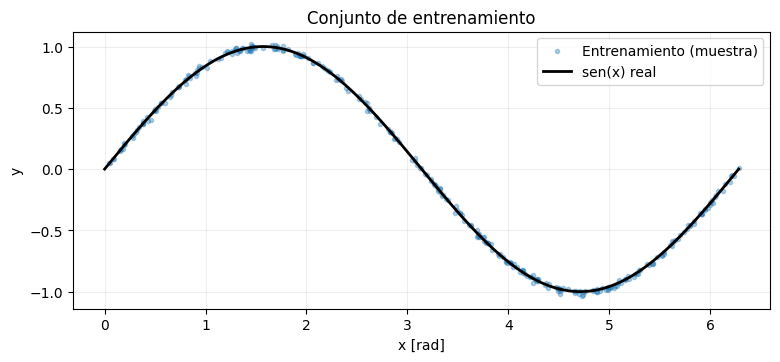

Formas: (1600, 1) (1600, 1) (320, 1) (256, 1)


In [2]:
rng = np.random.default_rng(SEED)
X_train = rng.uniform(0.0, 2*np.pi, size=(1600, 1)).astype(np.float32)
y_train = (np.sin(X_train) + rng.normal(0, 0.015, size=(1600, 1))).astype(np.float32)
X_val = rng.uniform(0.0, 2*np.pi, size=(320, 1)).astype(np.float32)
y_val = np.sin(X_val).astype(np.float32)
X_test = np.linspace(0, 2*np.pi, 256, dtype=np.float32).reshape(-1, 1)
y_test = np.sin(X_test).astype(np.float32)

plt.figure(figsize=(9, 3.6))
plt.scatter(X_train[::5, 0], y_train[::5, 0], s=9, alpha=0.35, label='Entrenamiento (muestra)')
plt.plot(X_test[:, 0], y_test[:, 0], color='black', linewidth=2, label='sen(x) real')
plt.xlabel('x [rad]'); plt.ylabel('y'); plt.title('Conjunto de entrenamiento')
plt.legend(); plt.grid(alpha=.2); plt.show()
print('Formas:', X_train.shape, y_train.shape, X_val.shape, X_test.shape)

## 2. Definir y entrenar el modelo

Una red pequeña **1 → 16 → 16 → 1**, con activaciones `tanh`, basta para ilustrar la aproximación de una función continua. La red se entrena **en la nube**; Arduino solo ejecutará inferencia.

`EarlyStopping` detiene el entrenamiento si deja de mejorar el error de validación. El número real de épocas depende de la ejecución.

Model: "seno_tinyml"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 965 (3.77 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644 (2.52 KB)

Épocas ejecutadas: 84


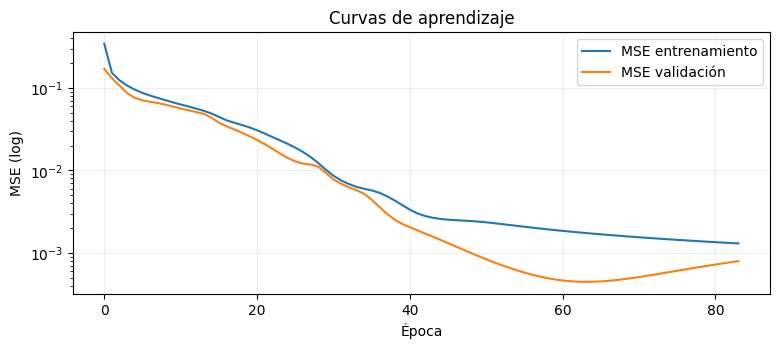

In [3]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,), dtype=tf.float32),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(1),
], name='seno_tinyml')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae'],
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )],
)
model.summary()
print('Épocas ejecutadas:', len(history.history['loss']))
plt.figure(figsize=(9, 3.4))
plt.plot(history.history['loss'], label='MSE entrenamiento')
plt.plot(history.history['val_loss'], label='MSE validación')
plt.yscale('log'); plt.xlabel('Época'); plt.ylabel('MSE (log)')
plt.title('Curvas de aprendizaje'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 3. Evaluar el modelo de TensorFlow (float32)

Calculamos RMSE y MAE sobre una rejilla de prueba separada. Estos resultados son la referencia para medir la pérdida ocasionada por la cuantización.

Modelo float32: {
  "RMSE": 0.02173098362982273,
  "MAE": 0.017213940620422363,
  "Error_max": 0.059465136379003525
}


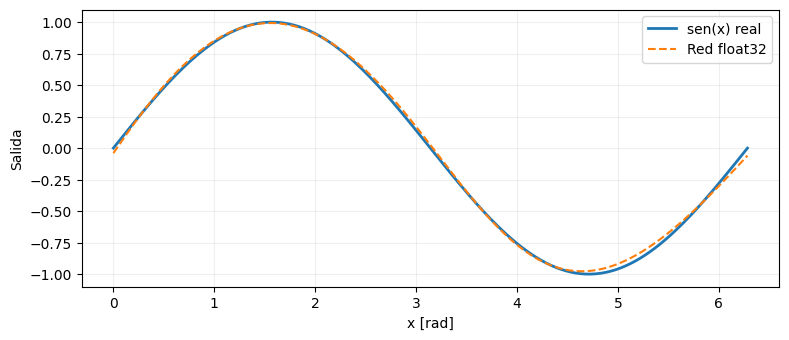

In [4]:
pred_fp32 = model.predict(X_test, verbose=0).reshape(-1)
y_true = y_test.reshape(-1)

def error_metrics(reference, prediction):
    return {
        'RMSE': float(np.sqrt(np.mean((reference - prediction)**2))),
        'MAE': float(np.mean(np.abs(reference - prediction))),
        'Error_max': float(np.max(np.abs(reference - prediction))),
    }

metric_fp32 = error_metrics(y_true, pred_fp32)
print('Modelo float32:', json.dumps(metric_fp32, indent=2))
plt.figure(figsize=(9, 3.6))
plt.plot(X_test[:, 0], y_true, label='sen(x) real', linewidth=2)
plt.plot(X_test[:, 0], pred_fp32, '--', label='Red float32')
plt.xlabel('x [rad]'); plt.ylabel('Salida'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 4. Cuantización ENTERA completa (INT8)

`Optimize.DEFAULT` junto con un **representative dataset** permite calibrar activaciones. Al establecer `TFLITE_BUILTINS_INT8` y forzar entrada y salida `tf.int8`, evitamos que Arduino tenga que calcular entradas o salidas en coma flotante dentro del grafo.

**Importante:** la cuantización no se reduce a convertir bytes; en Arduino hay que aplicar las escalas y los ceros (`scale` y `zero_point`) a los datos de entrada y salida.

In [5]:
def representative_data():
    for x in np.linspace(0, 2*np.pi, 256, dtype=np.float32):
        yield [np.array([[x]], dtype=np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
model_file = OUTPUT / 'modelo_seno_int8.tflite'
model_file.write_bytes(tflite_model)
print('Tamaño del modelo INT8:', len(tflite_model), 'bytes')
print('Archivo:', model_file)

# La inspección de operadores ayuda a diagnosticar incompatibilidades con TFLM.
try:
    tf.lite.experimental.Analyzer.analyze(model_content=tflite_model)
except Exception as exc:
    print('La visualización de operadores no está disponible:', type(exc).__name__, exc)

INFO:tensorflow:Assets written to: C:\Users\listo\AppData\Local\Temp\tmpoawtsfsf\assets


INFO:tensorflow:Assets written to: C:\Users\listo\AppData\Local\Temp\tmpoawtsfsf\assets


Saved artifact at 'C:\Users\listo\AppData\Local\Temp\tmpoawtsfsf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2929303651056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2929267521872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2929303474720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2929267107760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2929303474240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2929303474000: TensorSpec(shape=(), dtype=tf.resource, name=None)
Tamaño del modelo INT8: 3704 bytes
Archivo: tinyml_seno\modelo_seno_int8.tflite
=== TFLite ModelAnalyzer ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the FULLY_CONNECTED op takes
tensor #0 and 

c:\Users\listo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tensorflow\lite\python\convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


## 5. Verificar el INT8 con el intérprete TFLite en Colab

Esta prueba **sí ejecuta el modelo exportado** (no el objeto de Keras). Verifica tipos, escalas, `zero_point`, valores y el error frente a $\sin(x)$. La ejecución con TFLite en Colab **no sustituye la prueba física en el microcontrolador**, pero permite detectar errores de conversión antes de compilar.

Entrada: [1, 1] INT8, scale= 0.02463994361460209 zero= -128
Salida:  [1, 1] INT8, scale= 0.007726073265075684 zero= -2
Modelo INT8: {
  "RMSE": 0.06194637715816498,
  "MAE": 0.048280827701091766,
  "Error_max": 0.19864624738693237
}
Diferencia RMSE INT8 - float32: 0.04021539352834225


c:\Users\listo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tensorflow\lite\python\interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


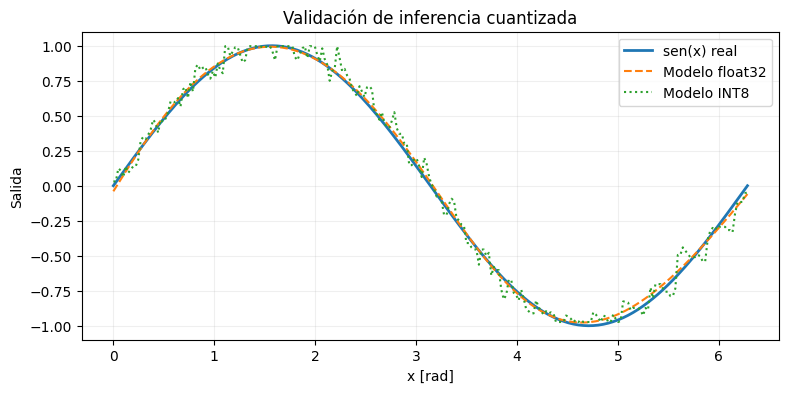

In [6]:
lite = tf.lite.Interpreter(model_content=tflite_model)
lite.allocate_tensors()
inp = lite.get_input_details()[0]
out = lite.get_output_details()[0]
assert inp['dtype'] == np.int8, f"Entrada inesperada: {inp['dtype']}"
assert out['dtype'] == np.int8, f"Salida inesperada: {out['dtype']}"
in_scale, in_zero = inp['quantization']
out_scale, out_zero = out['quantization']
assert in_scale > 0 and out_scale > 0
print('Entrada:', inp['shape'].tolist(), 'INT8, scale=', in_scale, 'zero=', in_zero)
print('Salida: ', out['shape'].tolist(), 'INT8, scale=', out_scale, 'zero=', out_zero)

def predict_tflite(x_values):
    predictions = []
    for value in np.asarray(x_values).reshape(-1):
        q = int(np.clip(np.rint(float(value)/in_scale + in_zero), -128, 127))
        lite.set_tensor(inp['index'], np.array([[q]], dtype=np.int8))
        lite.invoke()
        result = int(lite.get_tensor(out['index']).reshape(-1)[0])
        predictions.append((result - out_zero) * out_scale)
    return np.asarray(predictions, dtype=np.float32)

pred_int8 = predict_tflite(X_test)
metric_int8 = error_metrics(y_true, pred_int8)
print('Modelo INT8:', json.dumps(metric_int8, indent=2))
print('Diferencia RMSE INT8 - float32:', metric_int8['RMSE'] - metric_fp32['RMSE'])

plt.figure(figsize=(9, 4))
plt.plot(X_test[:, 0], y_true, label='sen(x) real', linewidth=2)
plt.plot(X_test[:, 0], pred_fp32, '--', label='Modelo float32')
plt.plot(X_test[:, 0], pred_int8, ':', label='Modelo INT8')
plt.xlabel('x [rad]'); plt.ylabel('Salida'); plt.title('Validación de inferencia cuantizada')
plt.legend(); plt.grid(alpha=.2); plt.show()

## 6. Exportar automáticamente `model.h`

El modelo `.tflite` es binario; **Arduino IDE no lo puede enlazar como una variable por sí solo**. Lo convertimos a `const unsigned char g_model[]`, con alineación de 16 bytes.

**No copies manualmente miles de números:** el siguiente paso genera el archivo a partir del modelo real entrenado y cuantizado.

In [7]:
def tflite_to_header(blob, symbol='g_model'):
    body = '\n'.join(
        '  ' + ', '.join(f'0x{b:02x}' for b in blob[i:i+12]) + ','
        for i in range(0, len(blob), 12)
    )
    return (f'#pragma once\n#include <stdint.h>\n\n'
            f'// Modelo INT8 generado por Google Colab. No editar.\n'
            f'alignas(16) const unsigned char {symbol}[] = {{\n{body}\n}};\n'
            f'const unsigned int {symbol}_len = sizeof({symbol});\n')

header_file = OUTPUT / 'model.h'
header_file.write_text(tflite_to_header(tflite_model), encoding='utf-8')
assert 'alignas(16)' in header_file.read_text()
print('Header generado:', header_file)
print('Primeros 12 bytes:', list(tflite_model[:12]))
print('Tamaño de model.h:', header_file.stat().st_size, 'bytes')

Header generado: tinyml_seno\model.h
Primeros 12 bytes: [32, 0, 0, 0, 84, 70, 76, 51, 0, 0, 0, 0]
Tamaño de model.h: 23344 bytes


## 7. Generar el sketch de Arduino IDE

El sketch incluye el intérprete TFLM mediante `Chirale_TensorFlowLite`, inicializa una **arena de tensores de 24 KiB**, y convierte correctamente los datos `float` a INT8 y viceversa usando los parámetros del propio modelo.

Usamos `AllOpsResolver` para simplificar esta primera práctica. **En un curso avanzado conviene reemplazarlo por `MicroMutableOpResolver` con únicamente las operaciones requeridas** y comparar el tamaño de Flash.

El programa recorre el intervalo $[0,2\pi]$ y emite dos series (`real` y `pred`) al **Serial Plotter**, sin necesidad de sensores. La arena y los kernels pueden ajustarse después de la primera compilación.

In [8]:
SKETCH = r'''// TinyML 2026 | Aproximacion de sin(x) con un modelo INT8 propio.
// Placas objetivo: Arduino Nano 33 BLE Sense / Sense Rev2 (nRF52840).
// Biblioteca: Chirale_TensorFlowLite 2.0.0.
#include <Arduino.h>
#include <math.h>
#include <stdint.h>
#include <Chirale_TensorFlowLite.h>
#include "tensorflow/lite/micro/all_ops_resolver.h"
#include "tensorflow/lite/micro/micro_interpreter.h"
#include "tensorflow/lite/schema/schema_generated.h"
#include "model.h"

constexpr int kTensorArenaSize = 24 * 1024;
alignas(16) uint8_t tensor_arena[kTensorArenaSize];

const tflite::Model* net = nullptr;
tflite::MicroInterpreter* interpreter = nullptr;
TfLiteTensor* input_tensor = nullptr;
TfLiteTensor* output_tensor = nullptr;

void fatal(const char* message) {
  Serial.println(message);
  while (true) { delay(1000); }
}

void setup() {
  Serial.begin(115200);
  unsigned long inicio = millis();
  while (!Serial && millis() - inicio < 3000) { delay(10); }

  net = tflite::GetModel(g_model);
  if (net->version() != TFLITE_SCHEMA_VERSION) {
    fatal("ERROR: version de schema incompatible.");
  }

  static tflite::AllOpsResolver resolver;
  static tflite::MicroInterpreter static_interpreter(
      net, resolver, tensor_arena, kTensorArenaSize);
  interpreter = &static_interpreter;

  if (interpreter->AllocateTensors() != kTfLiteOk) {
    fatal("ERROR: AllocateTensors. Revisar arena/ops/versiones.");
  }
  input_tensor = interpreter->input(0);
  output_tensor = interpreter->output(0);
  if (input_tensor->type != kTfLiteInt8 || output_tensor->type != kTfLiteInt8) {
    fatal("ERROR: se esperaba entrada y salida INT8.");
  }
  if (input_tensor->params.scale <= 0 || output_tensor->params.scale <= 0) {
    fatal("ERROR: escalas de cuantizacion invalidas.");
  }
  Serial.println("Inicializacion completa; abrir Herramientas > Serial Plotter.");
}

void loop() {
  static uint16_t paso = 0;
  constexpr uint16_t kPasos = 128;
  constexpr float kDosPi = 6.28318530718f;
  float x = kDosPi * (float)(paso % kPasos) / (float)(kPasos - 1);
  paso++;

  // Cuantizacion: q = round(x / scale) + zero_point, saturada a [-128,127].
  const float s_in = input_tensor->params.scale;
  const int z_in = input_tensor->params.zero_point;
  int qx = (int)lroundf(x / s_in) + z_in;
  if (qx < -128) qx = -128;
  if (qx >  127) qx =  127;
  input_tensor->data.int8[0] = (int8_t)qx;

  if (interpreter->Invoke() != kTfLiteOk) {
    fatal("ERROR: fallo de inferencia.");
  }

  int8_t qy = output_tensor->data.int8[0];
  float y = (float)(qy - output_tensor->params.zero_point)
            * output_tensor->params.scale;
  float real = sinf(x);

  // Salida apta para Arduino IDE Serial Plotter.
  Serial.print("real:"); Serial.print(real, 4);
  Serial.print(",pred:"); Serial.println(y, 4);
  delay(80);
}'''

sketch_dir = OUTPUT / 'TinyML_Seno_Nano33BLE'
sketch_dir.mkdir(exist_ok=True)
ino_file = sketch_dir / 'TinyML_Seno_Nano33BLE.ino'
ino_file.write_text(SKETCH, encoding='utf-8')
(sketch_dir / 'model.h').write_bytes(header_file.read_bytes())
print('Sketch:', ino_file)
print('Carpeta Arduino:', sketch_dir)
print('Bytes del sketch:', ino_file.stat().st_size)

Sketch: tinyml_seno\TinyML_Seno_Nano33BLE\TinyML_Seno_Nano33BLE.ino
Carpeta Arduino: tinyml_seno\TinyML_Seno_Nano33BLE
Bytes del sketch: 2869


## 8. Instalación de Arduino IDE y biblioteca (pasos detallados)

**A. Instalar Arduino IDE 2.x**

1. Descarga **Arduino IDE 2.x** desde [arduino.cc/en/software](https://www.arduino.cc/en/software) e instálalo en tu computadora (no dentro de Colab).
2. Abre **Herramientas → Placa → Gestor de placas** y busca **Arduino Mbed OS Nano Boards**. Instala ese paquete de soporte.
3. Conecta la tarjeta por USB; en **Herramientas → Placa** selecciona **Arduino Nano 33 BLE** (la opción del núcleo Mbed para Nano 33 BLE / Sense / Sense Rev2 según el paquete instalado). Elige el puerto serie que aparece al conectar la placa.
4. Abre **Herramientas → Administrar bibliotecas** y busca **Chirale**. Instala **Chirale_TensorFlowLite** (versión 2.0.0 si está disponible). En algunos listados el nombre aparece capitalizado como `Chirale_TensorFLowLite`; el header que utiliza el programa es `Chirale_TensorFlowLite.h`.
5. Si la biblioteca no aparece en el Gestor: descarga el ZIP desde [spaziochirale/Chirale_TensorFlowLite](https://github.com/spaziochirale/Chirale_TensorFlowLite) (botón **Code → Download ZIP**) y usa **Programa → Incluir librería → Añadir biblioteca .ZIP…**. Reinicia el IDE si fuera necesario. **No instales simultáneamente varias bibliotecas que exporten las mismas cabeceras de TFLM** (`Arduino_TensorFlowLite` archivada, Chirale, etc.) para evitar colisiones de dependencias.

**B. Abrir el proyecto generado**

6. Ejecuta todas las celdas hasta el final, descarga **`TinyML_Seno_Arduino_Nano33BLE.zip`** y **descomprímelo** (no abras el ZIP directamente como sketch).
7. En Arduino IDE: **Archivo → Abrir → `TinyML_Seno_Nano33BLE/TinyML_Seno_Nano33BLE.ino`**. Comprueba que **`model.h`** esté en la misma carpeta que el archivo `.ino` (lo genera automáticamente este notebook).
8. Haz clic en **Verificar** para compilar y después **Subir**.
9. Abre **Herramientas → Serial Plotter**, configura **115200 baudios** y comprueba las dos curvas `real` y `pred`.

**C. Si trabajas en Ubuntu/Linux**

- Verifica el puerto con `ls /dev/ttyACM* /dev/ttyUSB* 2>/dev/null`.
- Si no tienes permisos para abrir el puerto, suele ayudar: `sudo usermod -aG dialout "$USER"`; luego **cierra sesión y vuelve a iniciarla**. No uses `chmod 777` como solución permanente.
- Si la placa no carga, prueba pulsar dos veces el botón reset para entrar al bootloader y vuelve a elegir el puerto.

**D. Resolución de errores frecuentes**

| Síntoma | Causa posible | Comprobación / solución |
|---|---|---|
| `Chirale_TensorFlowLite.h: No such file` | Biblioteca ausente o instalada en carpeta incorrecta | Reinstalar biblioteca y reiniciar IDE |
| `tensorflow/lite/micro/...: No such file` | Biblioteca equivocada o incompleta | Quitar duplicados y verificar distribución Chirale |
| `schema incompatible` | Modelo y runtime usan esquema TFLite distinto | Revisar versiones del conversor de Colab y del runtime de Arduino |
| `AllocateTensors failed` | Arena insuficiente **o** operador/versiones incompatibles | Aumentar `kTensorArenaSize` y revisar logs/operadores |
| El sketch compila pero no aparece una curva | Puerto/baudios incorrectos, mensaje de error o cable USB de solo carga | Abrir el monitor serie a 115200 y comprobar mensajes |
| Resultados muy alejados de `sin(x)` | Error de cuantización o uso de otro `model.h` | Revisar los metadatos de INT8 y copiar el header generado |

> **Advertencia metodológica:** la biblioteca Chirale proviene de 2024 y no garantiza compatibilidad con todas las versiones futuras del conversor TensorFlow. El notebook valida la inferencia TFLite en Python; **la compilación y la ejecución en la placa son verificaciones que debe realizar cada estudiante**. Si un modelo generado por TensorFlow actual usa versiones de operadores más recientes que la biblioteca Arduino, hay que ajustar la versión de herramientas o reconstruir TFLM, no copiar arbitrariamente bytes a otro formato.